# Retail Sales Performance Analysis
Upload your dataset (`retail_sales.csv`) to the same folder in Jupyter before running the cells below.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the dataset
df = pd.read_csv("retail_sales.csv")  # or pd.read_excel("retail_sales.xlsx")

print("Shape:", df.shape)
display(df.head())

Shape: (502, 8)


,Order_ID,Date,Product,Category,City,Quantity,Unit_Price,Total_Sales
0,1,2026-01-01,Cookware Set,Home & Kitchen,Ghaziabad,3,1800,5400
1,2,2026-01-01,Shirt,Clothes,Pune,1,950,950
2,3,2026-01-02,Kurti,Clothes,Mumbai,3,1100,3300
3,4,2026-01-03,Sneakers,Footwear,Noida,4,2200,8800
4,5,2026-01-03,Headphones,Electronics,Lucknow,1,2500,2500


In [9]:
# 2. Data cleaning & feature engineering
df = df.drop_duplicates()

# Parse dates safely
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date", "Total_Sales"])

# Fill missing quantity with 0 if needed
if "Quantity" in df.columns:
    df["Quantity"] = df["Quantity"].fillna(0)

# Ensure Unit_Price & Total_Sales are numeric
if "Unit_Price" in df.columns and "Quantity" in df.columns:
  df["Total_Sales"] = df["Total_Sales"].fillna(
      df["Quantity"] * df["Unit_Price"]
  )

df["Year_Month"] = df["Date"].dt.to_period("M").astype(str)
print("Data cleaned successfully.")

Data cleaned successfully.


In [11]:
# 3. Core KPIs
total_sales = df["Total_Sales"].sum()
total_orders = len(df)
avg_order_value = df["Total_Sales"].mean()

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value (AOV): {avg_order_value:,.2f}")

if "Profit" in df.columns:
    total_profit = df["Profit"].sum()
    overall_margin = (total_profit / total_sales) * 100 if total_sales else 0
    print(f"Total Profit: {total_profit:,.2f} ({overall_margin:.2f}% margin)")

Total Sales: 3,045,600.00
Total Orders: 500
Average Order Value (AOV): 6,091.20


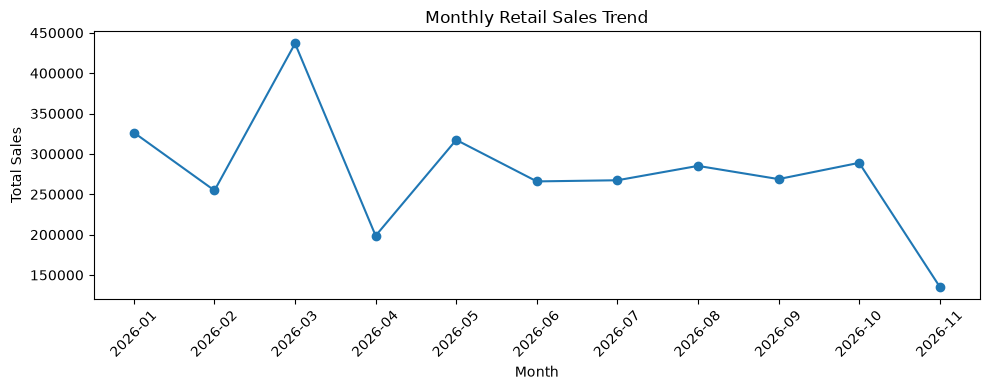

In [13]:
# 4. Monthly sales trend
monthly_sales = df.groupby("Year_Month", as_index=False)["Total_Sales"].sum()

plt.figure(figsize=(10, 4))
plt.plot(monthly_sales["Year_Month"], monthly_sales["Total_Sales"], marker="o")
plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Sales by Category:
 Category
Electronics       1040600
Clothes            713350
Footwear           466100
Home & Kitchen     465750
Accessories        359800
Name: Total_Sales, dtype: int64


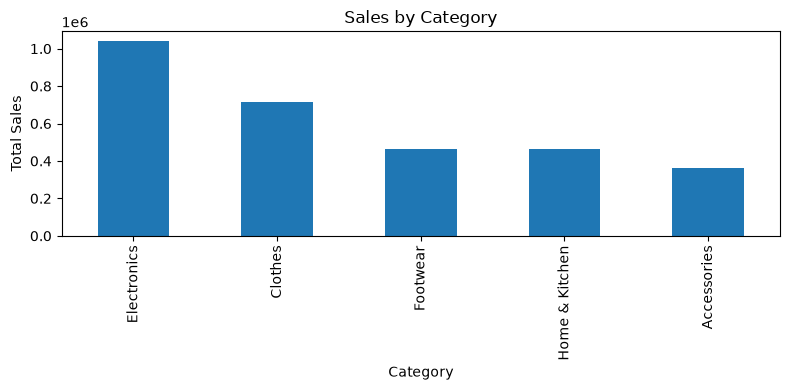


Sales by City:
 City
Pune         356250
Lucknow      348200
Bengaluru    347250
Delhi        336300
Ghaziabad    298950
Kanpur       295050
Mumbai       279950
Jaipur       271050
Noida        258800
Kolkata      253800
Name: Total_Sales, dtype: int64


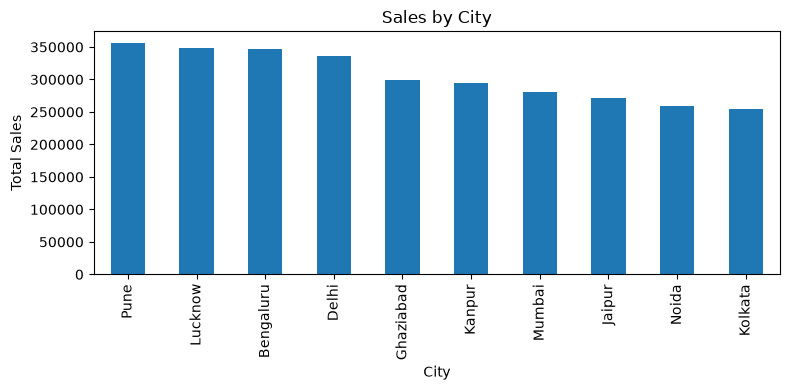

In [17]:
# 5. Top categories & regions
if "Category" in df.columns:
    cat_perf = df.groupby("Category")["Total_Sales"].sum().sort_values(ascending=False)
    print("\nSales by Category:\n", cat_perf)

    cat_perf.plot(
        kind="bar", figsize=(8, 4), title="Sales by Category", ylabel="Total Sales"
    )
    plt.tight_layout()
    plt.show()

if "City" in df.columns:
    city_perf = df.groupby("City")["Total_Sales"].sum().sort_values(ascending=False)
    print("\nSales by City:\n", city_perf)
    
    city_perf.plot(
        kind="bar", figsize=(8, 4), title="Sales by City", ylabel="Total Sales"
    )
    plt.tight_layout()
    plt.show()
    